# **Практична робота №5**

## Тема: Оцінка надійності програмного забезпечення

### **1. Мета роботи**

Використовуючи спеціалізовані бібліотеки та мову програмування Python, дослідити методи оцінки надійності програмного забезпечення, реалізувати відповідні алгоритми, проаналізувати отримані результати та зробити висновки.

### **2. Теоретичні відомості**

Надійність програмного забезпечення - це здатність програми безвідмовно виконувати свої функції у визначених умовах протягом заданого проміжку часу.

Основні поняття:
- Fault (Bug) — дефект у програмному коді.
- Failure — прояв помилки під час роботи програми.
- MTBF — середній час між відмовами.
- MTTR — середній час відновлення після відмови.
- MTTF — середній час до виникнення відмови.
- POFOD — імовірність відмови під час отримання запиту.
- Availability — коефіцієнт готовності системи.

Для оцінювання надійності використовують аналітичні, емпіричні та експертні методи, а також моделі зростання надійності програмного забезпечення (SRGM).

### **3. Підготовка середовища**

Створюємо першу комірку Google Colab та встановлюємо необхідні бібліотеки.

In [1]:
!pip install numpy scipy matplotlib

Імпортуємо бібліотеки:

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from scipy import stats

print("Бібліотеки успішно підключено!")

Бібліотеки успішно підключено!


### **4. Модель Джелінського - Моранди**

**4.1. Теоретичні відомості**

Модель Джелінського - Моранди - це класична модель зростання надійності програмного забезпечення. Вона використовується для оцінки початкової кількості помилок у коді (N) та прогнозування інтенсивності відмов на основі інтервалів часу між появою помилок.

Основні припущення моделі:
1. Початкова кількість помилок до початку тестування дорівнює N.
2. Коли виявляється i-та помилка, вона одразу виправляється, не створюючи нових дефектів.
3. Кількість помилок, що залишилися, зменшується після кожного виправлення.
Інтенсивність відмов на i-му інтервалі часу визначається за формулою:
λᵢ = φ × [N − (i − 1)]


де:
- φ - коефіцієнт пропорційності;
- N - початкова кількість помилок;
- i - номер виявленої помилки.
Для пошуку параметрів N та φ використовується метод максимальної правдоподібності (Maximum Likelihood Estimation - MLE).

**4.2. Реалізація на Python**

Оскільки рівняння для знаходження N є нелінійним, використаємо бібліотеки NumPy та SciPy для чисельного розрахунку.

In [3]:
import numpy as np

times_between_failures = np.array(
    [10, 15, 22, 35, 40, 65, 80, 110, 150, 250],
    dtype=float
)

n = len(times_between_failures)

def log_likelihood(N):
    remaining = N - np.arange(n)

    if N <= n or np.any(remaining <= 0):
        return -np.inf

    phi = n / np.sum(remaining * times_between_failures)

    return np.sum(
        np.log(phi * remaining)
        - phi * remaining * times_between_failures
    )


possible_N = np.arange(n + 1, 10001)

likelihoods = np.array([
    log_likelihood(N) for N in possible_N
])

N_estimated = possible_N[np.argmax(likelihoods)]

remaining = N_estimated - np.arange(n)

phi_estimated = n / np.sum(
    remaining * times_between_failures
)

remaining_faults = N_estimated - n

print("Результати розрахунку за моделлю Джелінського-Моранди:")
print(f"Initial Faults (N): {N_estimated}")
print(f"Proportionality Constant (phi): {phi_estimated:.6f}")
print(f"Remaining Faults: {remaining_faults}")

Результати розрахунку за моделлю Джелінського-Моранди:
Initial Faults (N): 11
Proportionality Constant (phi): 0.003127
Remaining Faults: 1


**4.3. Результати розрахунку**

За результатами виконання програми отримано:
- Initial Faults (N): 11.
- Proportionality Constant (phi): 0.003127.
- Remaining Faults: 1.

**4.4. Аналіз результатів**

Початкова прогнозована кількість помилок у програмному забезпеченні становить 11. Після виявлення та виправлення 10 помилок залишається одна невиявлена помилка.

Інтервали часу між відмовами поступово збільшуються: від 10 до 250 одиниць часу. Це свідчить про підвищення надійності програмного забезпечення та зменшення інтенсивності виникнення відмов.

Отримані результати показують, що модель Джелінського - Моранди дозволяє оцінити кількість помилок та проаналізувати процес підвищення надійності програми.

### **5. Модель зростання надійності Гоела - Окумото**

**5.1. Теоретичні відомості**

Модель Гоела - Окумото використовується для прогнозування загальної кількості помилок у програмному забезпеченні та інтенсивності їх виявлення.

Функція середньої кількості відмов визначається формулою:
m(t) = a × (1 − e^(−b × t))


де:
- a - очікувана загальна кількість помилок у програмному забезпеченні;
- b - інтенсивність виявлення помилок;
- t - час тестування;
- m(t) - очікувана накопичена кількість виявлених помилок.
Для пошуку параметрів a та b використовується метод найменших квадратів за допомогою бібліотеки SciPy.

**5.2. Реалізація на Python**

Оптимальні параметри моделі
Прогнозована загальна кількість помилок (a): 104.18
Коефіцієнт виявлення помилок (b): 0.1737
Коефіцієнт детермінації (R²): 0.9979
Прогноз на 20-му тижні: 100.95


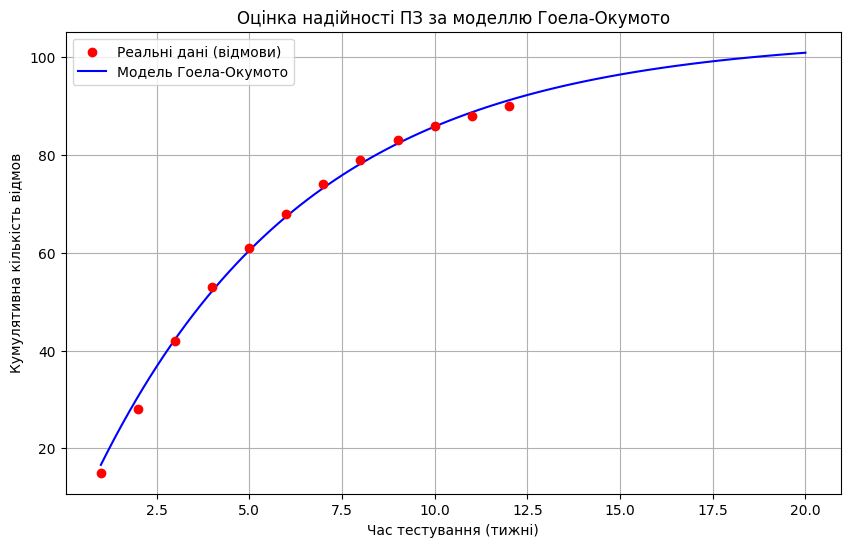

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit

time_weeks = np.array([
    1, 2, 3, 4, 5, 6,
    7, 8, 9, 10, 11, 12
])

cumulative_failures = np.array([
    15, 28, 42, 53, 61, 68,
    74, 79, 83, 86, 88, 90
])

def goel_okumoto_model(t, a, b):
    return a * (1 - np.exp(-b * t))


popt, pcov = curve_fit(
    goel_okumoto_model,
    time_weeks,
    cumulative_failures,
    p0=[100, 0.1],
    bounds=(0, np.inf),
    maxfev=10000
)

a_opt, b_opt = popt

predicted_actual = goel_okumoto_model(
    time_weeks, a_opt, b_opt
)

ss_res = np.sum(
    (cumulative_failures - predicted_actual) ** 2
)

ss_tot = np.sum(
    (cumulative_failures - np.mean(cumulative_failures)) ** 2
)

r_squared = 1 - ss_res / ss_tot

future_time = np.linspace(1, 20, 100)

predicted_failures = goel_okumoto_model(
    future_time, a_opt, b_opt
)

print("Оптимальні параметри моделі")

print(f"Прогнозована загальна кількість помилок (a): {a_opt:.2f}")
print(f"Коефіцієнт виявлення помилок (b): {b_opt:.4f}")
print(f"Коефіцієнт детермінації (R²): {r_squared:.4f}")

print(
    f"Прогноз на 20-му тижні: "
    f"{goel_okumoto_model(20, a_opt, b_opt):.2f}"
)

plt.figure(figsize=(10, 6))

plt.scatter(
    time_weeks,
    cumulative_failures,
    color='red',
    label='Реальні дані (відмови)',
    zorder=5
)

plt.plot(
    future_time,
    predicted_failures,
    color='blue',
    label='Модель Гоела-Окумото'
)

plt.title('Оцінка надійності ПЗ за моделлю Гоела-Окумото')
plt.xlabel('Час тестування (тижні)')
plt.ylabel('Кумулятивна кількість відмов')

plt.legend()
plt.grid(True)
plt.show()

**5.3. Результати розрахунку**

За результатами виконання програми отримано:
- Прогнозована загальна кількість помилок (a): 104.18.
- Коефіцієнт виявлення помилок (b): 0.1737.
- Коефіцієнт детермінації (R²): 0.9979.
- Прогнозована кількість помилок на 20-му тижні: 100.95.

**5.4. Аналіз результатів**

За результатами моделювання прогнозована загальна кількість помилок у програмному забезпеченні становить приблизно 104.18.

Коефіцієнт інтенсивності виявлення помилок дорівнює 0.1737. Це означає, що в процесі тестування кількість нових виявлених помилок поступово зменшується.

Коефіцієнт детермінації R² становить 0.9979, що свідчить про високу відповідність математичної моделі вихідним даним.

Згідно з прогнозом, на 20-му тижні тестування накопичена кількість виявлених помилок становитиме приблизно 100.95.

Отже, модель Гоела - Окумото дозволяє прогнозувати процес виявлення помилок та оцінювати подальше зростання надійності програмного забезпечення.

### **6. Оцінка метрик MTBF, MTTF та інтенсивності відмов (λ)**

**6.1. Теоретичні відомості**

Якщо є дані про точний час роботи системи між збоями (TBF - Time Between Failures), надійність програмного забезпечення можна оцінити за допомогою статистичних метрик.

Основні показники:

MTBF (Mean Time Between Failures) - середній час між відмовами.
MTBF = (t₁ + t₂ + ... + tₙ) / n


MTTF (Mean Time To Failure) - середній час до виникнення відмови.

Інтенсивність відмов (Failure Rate):
λ = 1 / MTBF


Функція надійності R(t) - ймовірність безвідмовної роботи протягом заданого часу.
R(t) = e^(−λ × t)


Для розрахунку довірчого інтервалу MTBF використовується розподіл хі-квадрат із рівнем довіри 95%.

**6.2. Реалізація на Python**

In [5]:
import numpy as np
from scipy import stats

tbf_data = np.array([
    120, 85, 210, 150, 300,
    95, 180, 240, 165, 140
])

mtbf = np.mean(tbf_data)

failure_rate = 1 / mtbf

confidence_level = 0.95

total_time = np.sum(tbf_data)
failures_count = len(tbf_data)

df = 2 * failures_count

chi2_lower = stats.chi2.ppf(
    (1 + confidence_level) / 2, df
)

chi2_upper = stats.chi2.ppf(
    (1 - confidence_level) / 2, df
)

mtbf_lower = (2 * total_time) / chi2_lower
mtbf_upper = (2 * total_time) / chi2_upper

def reliability_function(t, lam):
    return np.exp(-lam * t)


t_target = 100

r_100 = reliability_function(
    t_target, failure_rate
)

print("Статистичні метрики надійності")

print(f"Середній час між відмовами (MTBF): {mtbf:.2f} годин")

print(f"Інтенсивність відмов (lambda): {failure_rate:.6f} відмов/годину")

print(
    f"95% довірчий інтервал MTBF: "
    f"[{mtbf_lower:.2f}; {mtbf_upper:.2f}] годин"
)

print(
    f"Ймовірність безвідмовної роботи протягом "
    f"{t_target} годин: {r_100 * 100:.2f}%"
)

Статистичні метрики надійності
Середній час між відмовами (MTBF): 168.50 годин
Інтенсивність відмов (lambda): 0.005935 відмов/годину
95% довірчий інтервал MTBF: [98.63; 351.38] годин
Ймовірність безвідмовної роботи протягом 100 годин: 55.24%


**6.3. Результати розрахунку**

За результатами виконання програми отримано:
- Середній час між відмовами (MTBF): 168.50 годин.
- Інтенсивність відмов: 0.005935 відмов/годину.
- Нижня межа 95% довірчого інтервалу: 98.63 години.
- Верхня межа 95% довірчого інтервалу: 351.38 години.
- Ймовірність безвідмовної роботи протягом 100 годин: 55.24%.

**6.4. Аналіз результатів**

Середній час між відмовами програмного забезпечення становить 168.50 години. Інтенсивність відмов дорівнює 0.005935 відмов на годину.

95% довірчий інтервал для MTBF становить від 98.63 до 351.38 години.

Ймовірність безвідмовної роботи програмного забезпечення протягом 100 годин становить 55.24%.

Отримані результати дозволяють оцінити стабільність програмного забезпечення та спрогнозувати ймовірність його безперервної роботи протягом заданого часу.

Примітка: вихідні дані містять інтервали між відмовами, тому окремо визначити MTTF на їх основі неможливо без додаткових даних про час до першої відмови.

### **7. Загальний аналіз отриманих результатів**

У результаті виконання практичної роботи отримано такі показники:

1. Модель Джелінського - Моранди:
- Початкова кількість помилок: 11.
- Залишкова кількість помилок: 1.
2. Модель Гоела - Окумото:
- Прогнозована кількість помилок: 104.18.
- Коефіцієнт виявлення помилок: 0.1737.
3. Статистичні метрики:
- MTBF: 168.50 годин.
- Інтенсивність відмов: 0.005935 відмов/годину.
- Надійність протягом 100 годин: 55.24%.

### **8. Загальний висновок**

Під час виконання практичної роботи було досліджено методи оцінки надійності програмного забезпечення з використанням мови програмування Python та спеціалізованих бібліотек NumPy, SciPy і Matplotlib.

Було реалізовано модель Джелінського — Моранди, яка дозволяє оцінити початкову кількість помилок у програмному забезпеченні та визначити їх залишкову кількість після тестування.

За допомогою моделі Гоела — Окумото було виконано прогнозування загальної кількості помилок та побудовано графік залежності кількості виявлених помилок від часу тестування.

Також було розраховано статистичні показники надійності, зокрема MTBF, інтенсивність відмов, 95% довірчий інтервал та ймовірність безвідмовної роботи протягом 100 годин.

Отримані результати продемонстрували, що використання математичних моделей та статистичних методів дозволяє оцінювати надійність програмного забезпечення, прогнозувати можливі відмови та визначати необхідність подальшого тестування.